# Cyber Incident Dynamics and Threat Landscape in Germany
### An Empirical Multi-Source Analysis of Incident Patterns, Sectoral Vulnerabilities, and Geospatial Exposure

---

## Abstract and Research Framework

Following data harmonization and entity deduplication across four primary cyber threat repositories (*EuRepoC, UMD Cyber Events, Ransomware.live*, and *KonBriefing*), this study conducts a systematic exploratory analysis of verified cyber incidents affecting German entities.

The objective of this research is to evaluate data completeness, detect underlying associations among threat characteristics, and explore multi-dimensional interdependencies across micro (incident-level), meso (sector-year economic panel), and macro (geospatial) layers.

### Key Research Questions
1. **Data Completeness & Quality Diagnostics:** What is the attribute coverage of the incident dataset, and what structural factors explain remaining data gaps?
2. **Univariate Baselines:** How has the annual volume of incidents evolved, which economic sectors bear the highest burden, and which ransomware families are most prevalent?
3. **Bivariate Associations & Macroeconomic Correlations:** What statistical dependencies link attack attributes, and how does sector economic size correlate with incident frequency?
4. **Coupled Threat Mechanisms:** How does threat actor classification dictate operational motive, and how do attack types differ in terms of data theft versus operational disruption?
5. **Three-Variable Temporal Dynamics:** How has the distribution of incidents across economic sectors shifted over the 2017–2026 observation window?
6. **Four-Variable Economic-Threat Coupling:** How does sector gross value added (GVA) and workforce scale relative to incident counts and ransomware concentration?
7. **Five-Variable Threat Architecture:** How do threat actor origin, strategic motive, attack vector, target sector, and operational outcome chain together in a unified flow?
8. **Geospatial Exposure:** How does the geographical concentration of cyber incidents vary across the 16 German federal states when controlling for population density?

In [1]:
# Core data manipulation and statistical dependencies
import json
import pathlib
import warnings
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Static publication-quality visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive multi-dimensional and geospatial visualization libraries
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

# Suppress minor non-critical warnings for clean notebook presentation
warnings.filterwarnings("ignore")

# Configure Plotly renderers to support both interactive IDE viewports and exported HTML notebooks
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Establish consistent visual styling for all matplotlib and seaborn figures
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"

# Resolve filesystem paths reliably relative to execution directory
BASE_DIR = pathlib.Path.cwd()
if BASE_DIR.name == "notebooks":
    GERMANY_DIR = BASE_DIR.parent
elif (BASE_DIR / "germany").exists():
    GERMANY_DIR = BASE_DIR / "germany"
else:
    GERMANY_DIR = BASE_DIR

PREP_DIR = GERMANY_DIR / "data" / "prepared"
RAW_DIR = GERMANY_DIR / "data" / "raw"

# Load the verified base and AI-enriched incident datasets alongside the sector-year economic panel
df_orig = pd.read_csv(PREP_DIR / "germany_large_incidents.csv")
df = pd.read_csv(PREP_DIR / "germany_large_incidents_filled.csv")
df_panel = pd.read_csv(PREP_DIR / "germany_sector_year_panel.csv")

# ------------------------------------------------------------------------------
# Regional Demographics & Federal State Mapping
# ------------------------------------------------------------------------------
# Federal state names in the dataset are recorded in English; official GeoJSON boundaries
# and Destatis population/economic statistics utilize standard German nomenclature.
# We establish this mapping strictly for geospatial alignment and per-capita normalization.
BUNDESLAND_METRICS = {
    "North Rhine-Westphalia": {"de_name": "Nordrhein-Westfalen", "pop_mio": 18.19, "gdp_bn": 871.9},
    "Bavaria":                {"de_name": "Bayern",              "pop_mio": 13.44, "gdp_bn": 791.6},
    "Baden-Württemberg":      {"de_name": "Baden-Württemberg",   "pop_mio": 11.34, "gdp_bn": 650.2},
    "Lower Saxony":           {"de_name": "Niedersachsen",        "pop_mio":  8.16, "gdp_bn": 363.1},
    "Hesse":                  {"de_name": "Hessen",               "pop_mio":  6.42, "gdp_bn": 368.3},
    "Rhineland-Palatinate":   {"de_name": "Rheinland-Pfalz",      "pop_mio":  4.17, "gdp_bn": 184.0},
    "Saxony":                 {"de_name": "Sachsen",              "pop_mio":  4.09, "gdp_bn": 161.9},
    "Berlin":                 {"de_name": "Berlin",               "pop_mio":  3.78, "gdp_bn": 207.1},
    "Schleswig-Holstein":     {"de_name": "Schleswig-Holstein",   "pop_mio":  2.97, "gdp_bn": 126.8},
    "Brandenburg":            {"de_name": "Brandenburg",          "pop_mio":  2.58, "gdp_bn":  97.5},
    "Saxony-Anhalt":          {"de_name": "Sachsen-Anhalt",       "pop_mio":  2.18, "gdp_bn":  81.2},
    "Thuringia":              {"de_name": "Thüringen",            "pop_mio":  2.12, "gdp_bn":  78.1},
    "Hamburg":                {"de_name": "Hamburg",              "pop_mio":  1.91, "gdp_bn": 161.8},
    "Mecklenburg-Vorpommern": {"de_name": "Mecklenburg-Vorpommern","pop_mio": 1.63, "gdp_bn":  61.2},
    "Saarland":               {"de_name": "Saarland",             "pop_mio":  0.99, "gdp_bn":  42.8},
    "Bremen":                 {"de_name": "Bremen",               "pop_mio":  0.69, "gdp_bn":  41.4},
}

print(f"Loaded Enriched Incidents Dataset: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Loaded Sector-Year Balanced Panel: {df_panel.shape[0]} rows × {df_panel.shape[1]} columns")

Loaded Enriched Incidents Dataset: 2323 rows × 19 columns
Loaded Sector-Year Balanced Panel: 130 rows × 21 columns


---

## 1. Data Completeness & Quality Diagnostics

### Research Question 1
> *What is the attribute completeness of the incident dataset following controlled contextual enrichment, and what structural factors explain the remaining unpopulated cells?*

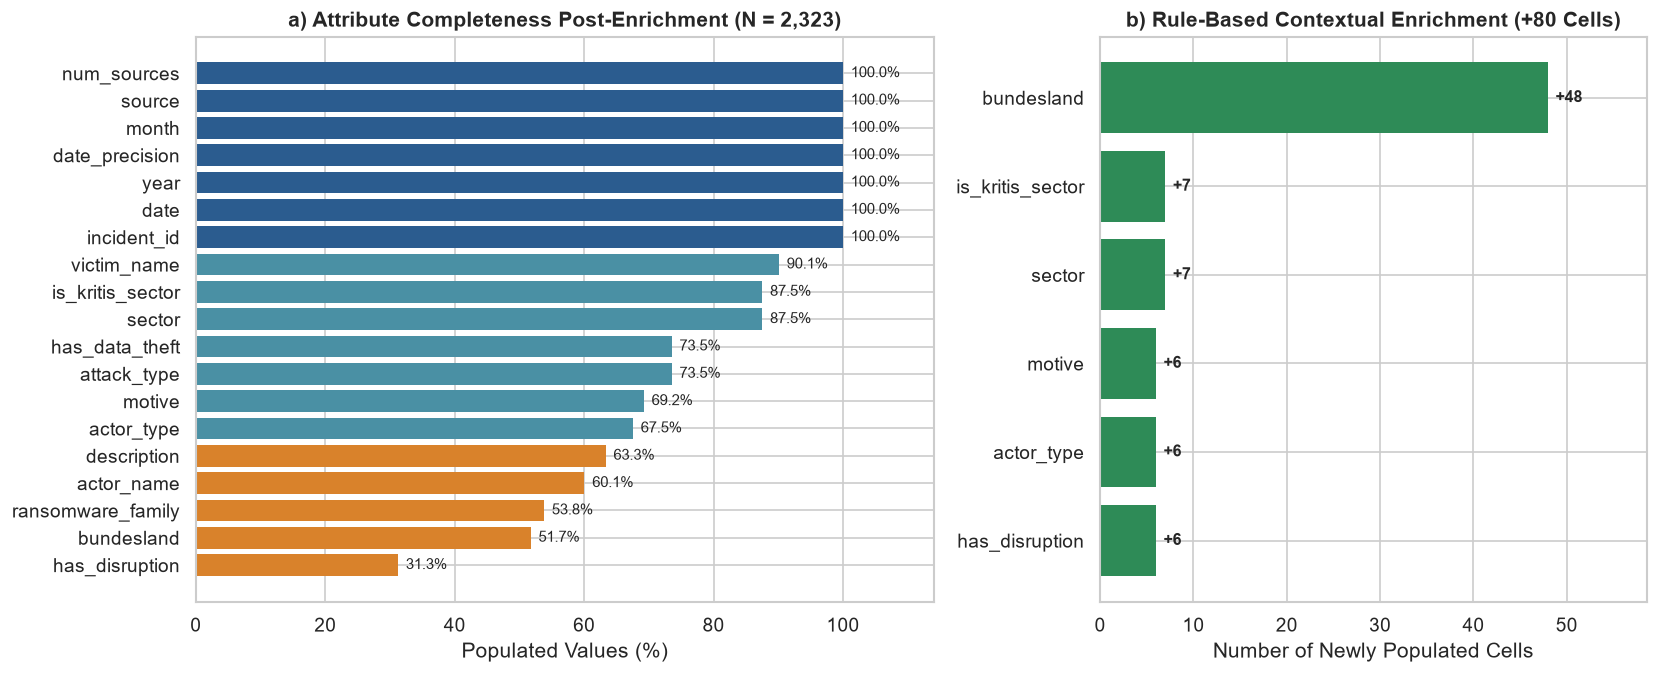

In [2]:
# Quantify attribute completeness comparing original and enriched builds
base_cols = list(df_orig.columns)
audit_records = []

for col in base_cols:
    present_orig = df_orig[col].notna().sum()
    present_fill = df[col].notna().sum()
    added_cells = present_fill - present_orig
    coverage_pct = (present_fill / len(df)) * 100
    audit_records.append({
        "attribute": col,
        "present_original": present_orig,
        "present_enriched": present_fill,
        "cells_added": added_cells,
        "coverage_pct": coverage_pct,
    })

audit_df = pd.DataFrame(audit_records).sort_values("coverage_pct", ascending=True)
added_df = audit_df[audit_df["cells_added"] > 0].sort_values("cells_added", ascending=True)

# Generate a two-panel diagnostic plot: overall coverage (left) and enrichment contribution (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})

# Visual coding: full coverage (100%), high coverage (>=65%), and structural partial coverage (<65%)
palette_cov = [
    "#2b5c8f" if pct == 100 else ("#4a90a4" if pct >= 65 else "#d9822b")
    for pct in audit_df["coverage_pct"]
]
bars1 = ax1.barh(audit_df["attribute"], audit_df["coverage_pct"], color=palette_cov, edgecolor="none")
ax1.set_xlim(0, 114)
ax1.set_xlabel("Populated Values (%)")
ax1.set_title("a) Attribute Completeness Post-Enrichment (N = 2,323)")

for bar, pct in zip(bars1, audit_df["coverage_pct"]):
    ax1.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height() / 2,
             f"{pct:.1f}%", va="center", fontsize=8.8)

bars2 = ax2.barh(added_df["attribute"], added_df["cells_added"], color="#2e8b57", edgecolor="none")
ax2.set_xlim(0, max(added_df["cells_added"]) * 1.22)
ax2.set_xlabel("Number of Newly Populated Cells")
ax2.set_title("b) Rule-Based Contextual Enrichment (+80 Cells)")

for bar, val in zip(bars2, added_df["cells_added"]):
    ax2.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
             f"+{int(val)}", va="center", fontweight="bold", fontsize=9.5)

plt.tight_layout()
plt.show()

### Analytical Findings & Interpretation
- **Completeness Profile:** Temporal and core identifier fields (`incident_id`, `date`, `year`, `month`, `source`) exhibit **100.0% coverage**. Entity names are identified in **90.1%** of records, target industry classification (`sector` and `is_kritis_sector`) reaches **87.5%**, and attack classification alongside data theft tags are available for **73.5%** of incidents.
- **Enrichment Yield:** High-precision rule-based extraction from unstructured incident texts populated **80 verified cells** without introducing label hallucination. The primary gain occurred in regional attribution (`bundesland`: **+48 cells**, raising coverage to **51.7%**), followed by sector attribution (**+7**) and threat motives (**+6**).
- **Structural Nature of Missingness:** Unpopulated fields reflect source domain constraints rather than random processing errors:
  - `ransomware_family` (**53.8%**) applies exclusively to extortion attacks; non-ransomware entries legitimately omit family identifiers.
  - `has_disruption` (**31.3%**) is conservative by design: extortion leak sites announce stolen archives but rarely disclose whether the victim's operations were paralyzed. Refraining from default imputation prevents artificial bias in downstream impact modeling.

---

## 2. Univariate Analysis: Longitudinal Trends, Sector Exposure & Malware Families

### Research Question 2
> *How has the volume of documented cyber incidents in Germany progressed over time, which industries represent the primary targets, and which ransomware families dominate the threat landscape?*

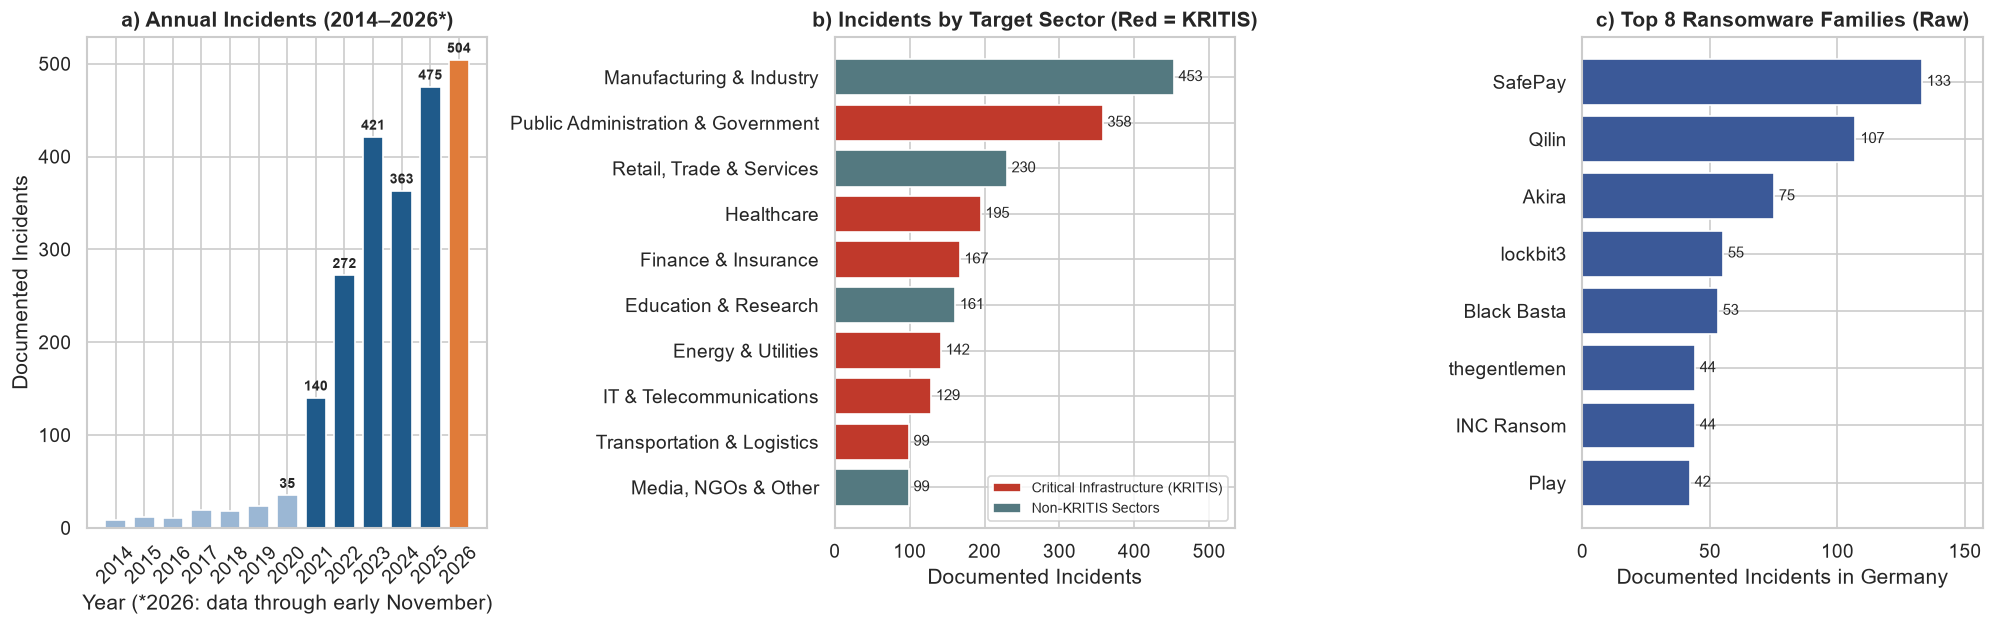

In [3]:
# Prepare three foundational univariate perspectives:
# 1) Longitudinal annual counts (2014–2026)
year_counts = df[df["year"] >= 2014]["year"].value_counts().sort_index()

# 2) Sector incident distribution categorized by Critical Infrastructure (KRITIS) designation
sec_summary = (
    df.dropna(subset=["sector"])
    .groupby(["sector", "is_kritis_sector"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=True)
)

# 3) Top 8 raw ransomware families as recorded in primary tracking sources
top_rw_raw = df["ransomware_family"].dropna().value_counts().head(8).sort_values(ascending=True)

fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.4))

# --- Panel a: Annual Trend (2014–2026) ---
colors_yr = ["#9bb7d4" if y < 2021 else ("#e07b39" if y == 2026 else "#1f5a8a") for y in year_counts.index]
axes[0].bar(year_counts.index.astype(str), year_counts.values, color=colors_yr, width=0.72)
axes[0].set_title("a) Annual Incidents (2014–2026*)")
axes[0].set_xlabel("Year (*2026: data through early November)")
axes[0].set_ylabel("Documented Incidents")
axes[0].tick_params(axis="x", rotation=45)
for idx, val in enumerate(year_counts.values):
    if val >= 35:
        axes[0].text(idx, val + 8, str(val), ha="center", fontsize=8.3, fontweight="bold")

# --- Panel b: Sector Distribution (Color-coded by KRITIS status) ---
kritis_palette = {True: "#c0392b", False: "#547980"}
bar_c_sec = [kritis_palette[bool(k)] for k in sec_summary["is_kritis_sector"]]
bars_sec = axes[1].barh(sec_summary["sector"], sec_summary["count"], color=bar_c_sec)
axes[1].set_title("b) Incidents by Target Sector (Red = KRITIS)")
axes[1].set_xlabel("Documented Incidents")
axes[1].set_xlim(0, max(sec_summary["count"]) * 1.18)
for bar, val in zip(bars_sec, sec_summary["count"]):
    axes[1].text(bar.get_width() + 6, bar.get_y() + bar.get_height() / 2,
                 str(val), va="center", fontsize=8.8)

from matplotlib.patches import Patch
axes[1].legend(
    handles=[
        Patch(facecolor="#c0392b", label="Critical Infrastructure (KRITIS)"),
        Patch(facecolor="#547980", label="Non-KRITIS Sectors"),
    ],
    loc="lower right",
    fontsize=8.2,
    frameon=True,
)

# --- Panel c: Top 8 Recorded Ransomware Families ---
bars_rw = axes[2].barh(top_rw_raw.index, top_rw_raw.values, color="#3b5998")
axes[2].set_title("c) Top 8 Ransomware Families (Raw)")
axes[2].set_xlabel("Documented Incidents in Germany")
axes[2].set_xlim(0, max(top_rw_raw.values) * 1.18)
for bar, val in zip(bars_rw, top_rw_raw.values):
    axes[2].text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
                 str(val), va="center", fontsize=8.8)

plt.tight_layout()
plt.show()

### Analytical Findings & Interpretation
- **Longitudinal Surge:** Annual incident reporting remained modest prior to 2021 ($\le 35$ incidents annually), before expanding dramatically to **140 in 2021**, **421 in 2023**, **475 in 2025**, and reaching **504 incidents** within the first ten months of **2026**. This trend reflects both the industrialization of Ransomware-as-a-Service (RaaS) operations and the broader monitoring scope of leak-site scraping engines.
- **Sector Hierarchy:** The incident volume is heavily concentrated in two sectors: **Manufacturing & Industry (453 incidents)** and **Public Administration & Government (358 incidents)**. Together, these two sectors account for **39.9%** of all recorded incidents in Germany. Over half of all sector-identified incidents impact designated **Critical Infrastructure (KRITIS)** entities.
- **Threat Actor Tools:** Among raw ransomware tags, **SafePay (133 incidents)**, **Qilin (107)**, and **Akira (75)** represent the most frequently observed strain identifiers, followed by **lockbit3 (55)**, **Black Basta (53)**, and **INC Ransom (44)**.

---

## 3. Bivariate Relationships: Categorical Associations & Macroeconomic Correlations

### Methodological Context
Incident datasets feature a combination of **nominal categories** (e.g., sector, attack type, threat motive) and **continuous panel indicators** (e.g., sectoral gross value added, employment, national cybercrime statistics). To avoid spurious linear correlations on nominal variables, we employ two complementary association metrics:
1. **Bias-corrected Cramér's $V$ ($V \in [0, 1]$)** for measuring association strength between nominal attributes on incident-level microdata.
2. **Pearson's correlation coefficient ($r \in [-1, 1]$)** for continuous economic indicators on the balanced sector-year panel (2014–2025).

### Research Question 3
> *Which incident attributes exhibit the strongest empirical coupling, and how does the macroeconomic scale of an industry correlate with its cyber incident frequency?*

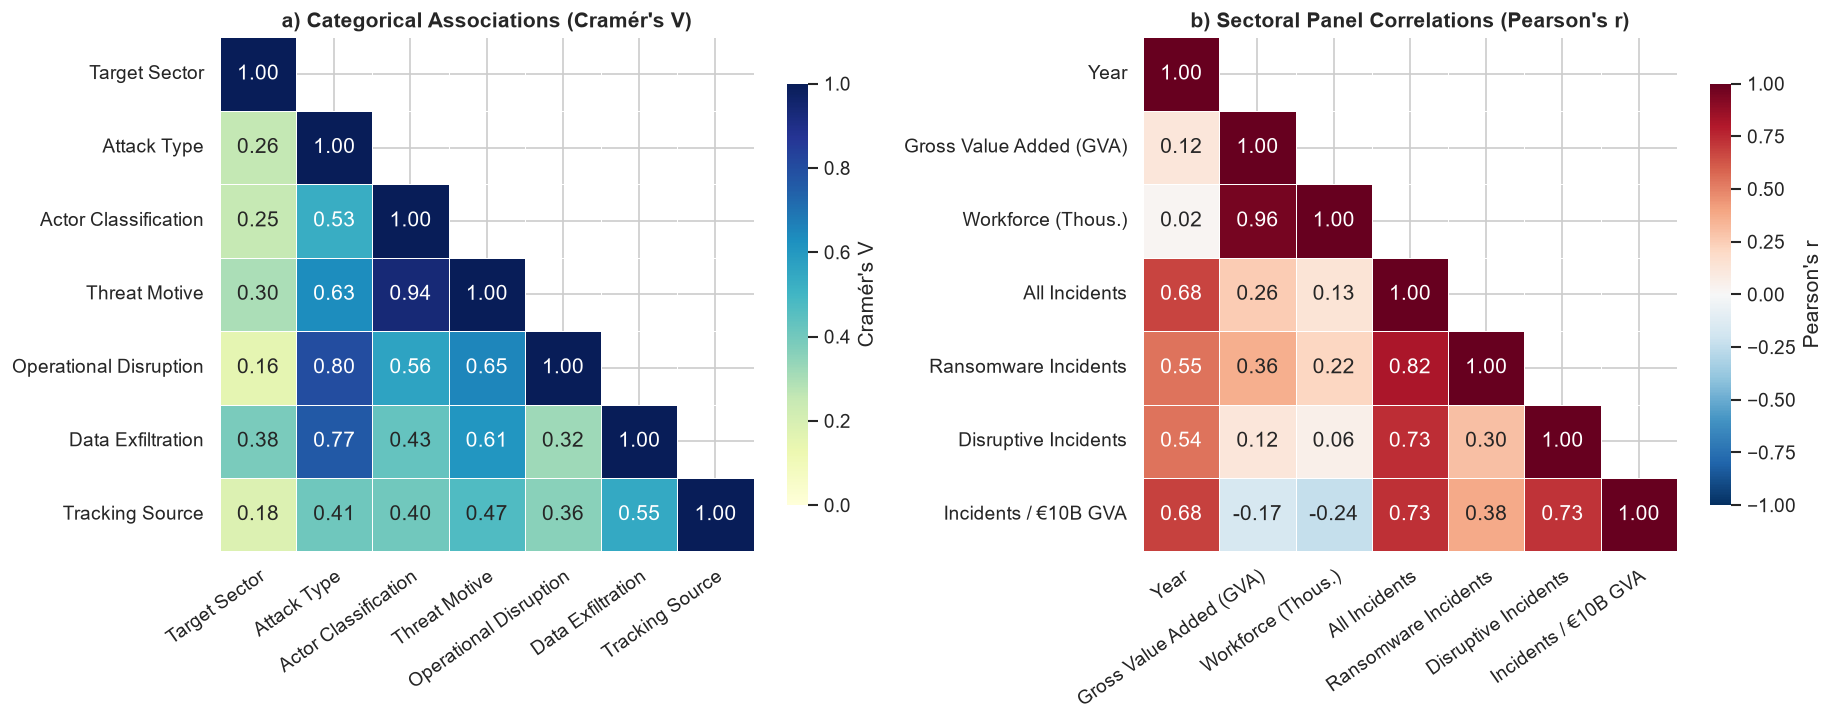

In [4]:
def cramers_v_corrected(df_in: pd.DataFrame, col_a: str, col_b: str) -> float:
    """Calculates bias-corrected Cramér's V on pairwise non-null records."""
    if col_a == col_b:
        return 1.0
    sub = df_in[[col_a, col_b]].dropna()
    if len(sub) < 10:
        return np.nan
    conf_mat = pd.crosstab(sub[col_a], sub[col_b])
    chi2 = chi2_contingency(conf_mat)[0]
    n = conf_mat.sum().sum()
    phi2 = chi2 / n
    r, k = conf_mat.shape
    # Bergsma-Wicher bias correction for finite-sample contingency tables
    phi2_corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(k_corr - 1, r_corr - 1)
    return float(np.sqrt(phi2_corr / denom)) if denom > 0 else 0.0


# Primary nominal attributes evaluated for mutual association
cat_vars = {
    "sector": "Target Sector",
    "attack_type": "Attack Type",
    "actor_type": "Actor Classification",
    "motive": "Threat Motive",
    "has_disruption": "Operational Disruption",
    "has_data_theft": "Data Exfiltration",
    "source": "Tracking Source",
}

cat_keys = list(cat_vars.keys())
cat_labels = list(cat_vars.values())
v_matrix = pd.DataFrame(index=cat_labels, columns=cat_labels, dtype=float)

for k1, l1 in cat_vars.items():
    for k2, l2 in cat_vars.items():
        v_matrix.loc[l1, l2] = cramers_v_corrected(df, k1, k2)

# Continuous macroeconomic and cybercrime indicators from the sector-year panel (2014–2025)
panel_clean = df_panel[df_panel["year"] <= 2025].copy()
num_vars = {
    "year": "Year",
    "sec_gva_eur_bn": "Gross Value Added (GVA)",
    "sec_employment_thousands": "Workforce (Thous.)",
    "documented_incidents": "All Incidents",
    "ransomware_incidents": "Ransomware Incidents",
    "disruptive_incidents": "Disruptive Incidents",
    "incidents_per_10bn_eur_gva": "Incidents / €10B GVA",
}
corr_matrix = panel_clean[list(num_vars.keys())].rename(columns=num_vars).corr(method="pearson")

# Dual heatmap display
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.2))

# Lower-triangle mask for clear, non-redundant presentation
mask_v = np.triu(np.ones_like(v_matrix, dtype=bool), k=1)
sns.heatmap(
    v_matrix, mask=mask_v, annot=True, fmt=".2f", cmap="YlGnBu",
    vmin=0, vmax=1, cbar_kws={"shrink": 0.82, "label": "Cramér's V"},
    linewidths=0.6, ax=ax1
)
ax1.set_title("a) Categorical Associations (Cramér's V)")
plt.setp(ax1.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")

mask_r = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask_r, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, center=0, cbar_kws={"shrink": 0.82, "label": "Pearson's r"},
    linewidths=0.6, ax=ax2
)
ax2.set_title("b) Sectoral Panel Correlations (Pearson's r)")
plt.setp(ax2.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")

plt.tight_layout()
plt.show()

### Analytical Findings & Interpretation
- **Categorical Couplings (Cramér's $V$):**
  - **Actor Classification $\leftrightarrow$ Threat Motive ($V = 0.94$):** Demonstrates near-deterministic alignment; actor category dictates strategic intent.
  - **Attack Type $\leftrightarrow$ Operational Disruption ($V = 0.80$) & Data Exfiltration ($V = 0.77$):** Confirms that operational consequences depend fundamentally on the technical attack archetype.
  - **Target Sector $\leftrightarrow$ Data Exfiltration ($V = 0.38$):** Reflects sectoral variation in data sensitivity and leak-site publication patterns.
- **Macroeconomic Correlations (Pearson's $r$):**
  - Sector **Gross Value Added (GVA)** displays a notable positive correlation with **Ransomware Incidents ($r = 0.36$)**, whereas its correlation with general disruptive attacks is substantially weaker ($r = 0.12$). Financially motivated actors disproportionately target economically substantial sectors.
  - Normalized attack intensity (**Incidents per €10B GVA**) is slightly negatively correlated with absolute sector size ($r = -0.17$), indicating that smaller critical sectors (e.g., Energy, Public Administration) face high proportional risk relative to their direct output.

---

## 4. In-Depth Coupling: Threat Actor Motives & Operational Consequences

Focusing on the two highest associations identified in Section 3 ($V = 0.94$ and $V = 0.80$), we analyze the exact mechanics connecting threat actor intent and consequence profiles.

### Research Question 4
> *How precisely does threat actor classification dictate attack motives, and how do technical attack types differentiate in their propensity to cause operational disruption versus data exfiltration?*

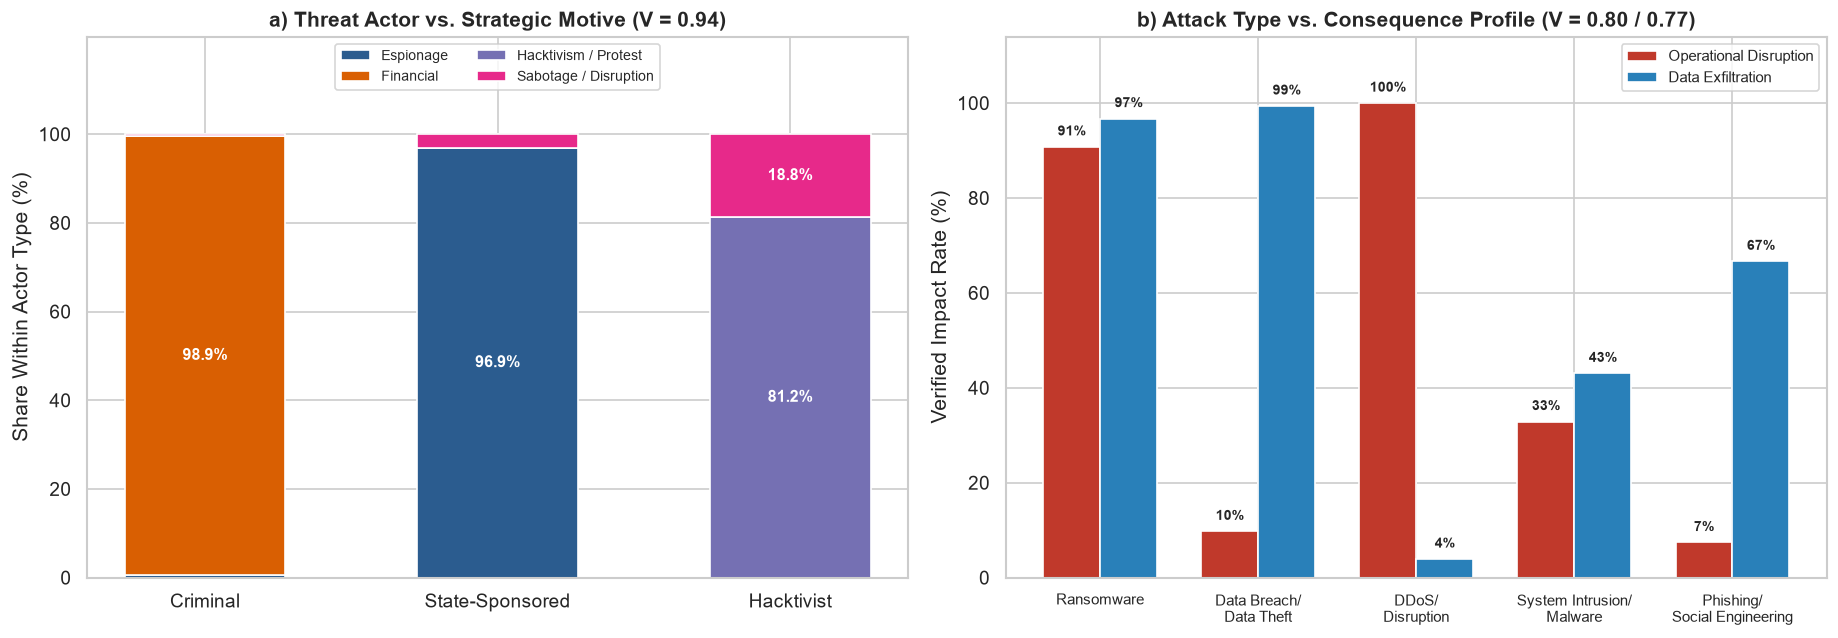

In [5]:
# 1) Relative contingency distribution: Threat Actor -> Motive
actor_filter = ["Criminal", "State-Sponsored", "Hacktivist"]
motive_filter = ["Financial", "Espionage", "Hacktivism / Protest", "Sabotage / Disruption"]

sub_am = df[df["actor_type"].isin(actor_filter) & df["motive"].isin(motive_filter)].copy()
ct_am_pct = pd.crosstab(sub_am["actor_type"], sub_am["motive"], normalize="index") * 100
ct_am_pct = ct_am_pct.reindex(["Criminal", "State-Sponsored", "Hacktivist"])

# 2) Disruption and exfiltration rates across specific attack types
attack_order = [
    "Ransomware",
    "Data Breach / Data Theft",
    "DDoS / Disruption",
    "System Intrusion / Malware",
    "Phishing / Social Engineering",
]

impact_data = []
for atk in attack_order:
    g = df[df["attack_type"] == atk]
    disr_rate = g["has_disruption"].dropna().astype(bool).mean() * 100 if g["has_disruption"].notna().sum() > 0 else 0.0
    theft_rate = g["has_data_theft"].dropna().astype(bool).mean() * 100 if g["has_data_theft"].notna().sum() > 0 else 0.0
    impact_data.append({
        "attack_type": atk.replace(" / ", "/\n"),
        "disruption_pct": disr_rate,
        "theft_pct": theft_rate,
    })

imp_df = pd.DataFrame(impact_data)

# Dual-panel visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.5))

# --- Panel a: 100% Stacked Bar: Actor Type vs Motive ---
palette_motive = ["#2b5c8f", "#d95f02", "#7570b3", "#e7298a"]
bottom = np.zeros(len(ct_am_pct))
for idx, col in enumerate(ct_am_pct.columns):
    vals = ct_am_pct[col].values
    ax1.bar(ct_am_pct.index, vals, bottom=bottom, label=col, color=palette_motive[idx], width=0.55)
    for b_idx, v in enumerate(vals):
        if v >= 8.0:
            ax1.text(b_idx, bottom[b_idx] + v / 2, f"{v:.1f}%",
                     ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    bottom += vals

ax1.set_ylim(0, 122)
ax1.set_yticks([0, 20, 40, 60, 80, 100])
ax1.set_ylabel("Share Within Actor Type (%)")
ax1.set_title("a) Threat Actor vs. Strategic Motive (V = 0.94)")
ax1.legend(loc="upper center", ncol=2, fontsize=8.6, frameon=True)

# --- Panel b: Grouped Bar: Attack Type vs Consequence ---
x = np.arange(len(imp_df))
width = 0.36
b1 = ax2.bar(x - width / 2, imp_df["disruption_pct"], width, label="Operational Disruption", color="#c0392b")
b2 = ax2.bar(x + width / 2, imp_df["theft_pct"], width, label="Data Exfiltration", color="#2980b9")

ax2.set_xticks(x)
ax2.set_xticklabels(imp_df["attack_type"], fontsize=8.8)
ax2.set_ylim(0, 114)
ax2.set_ylabel("Verified Impact Rate (%)")
ax2.set_title("b) Attack Type vs. Consequence Profile (V = 0.80 / 0.77)")
ax2.legend(loc="upper right", fontsize=8.8, frameon=True)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.8, f"{h:.0f}%",
                 ha="center", va="bottom", fontsize=8.2, fontweight="bold")

plt.tight_layout()
plt.show()

### Analytical Findings & Interpretation
- **Strategic Segregation of Actors:**
  - **Criminal Syndicates:** **98.9%** operate strictly for financial gain.
  - **State-Sponsored (APT) Groups:** **96.9%** engage in strategic espionage.
  - **Hacktivists:** Split between political protest (**81.2%**) and direct disruption/sabotage (**18.8%**).
- **The Double Extortion Paradigm:**
  - **DDoS** exclusively causes operational disruption (**100%**) with negligible exfiltration (**4%**).
  - **Data Breach / Theft** causes exfiltration (**99%**) with minimal operational downtime (**10%**).
  - **Ransomware** combines both mechanisms: among incidents with verified outcome reporting, **97% involved confirmed data exfiltration** and **91% caused system disruption**. This validates that modern ransomware campaigns in Germany systematically deploy double extortion, rendering offline backups insufficient on their own against extortion based on public data leaks.

---

## 5. Three-Variable Dynamics: Sector Exposure Across Time (2017–2026)

Combining **Year (X)**, **Target Sector (Y)**, and **Incident Count (Intensity)**, we examine whether sectoral risk exposure has remained stable or undergone structural transitions.

### Research Question 5
> *How has the distribution of documented cyber incidents across economic sectors shifted during the 2017–2026 observation window?*

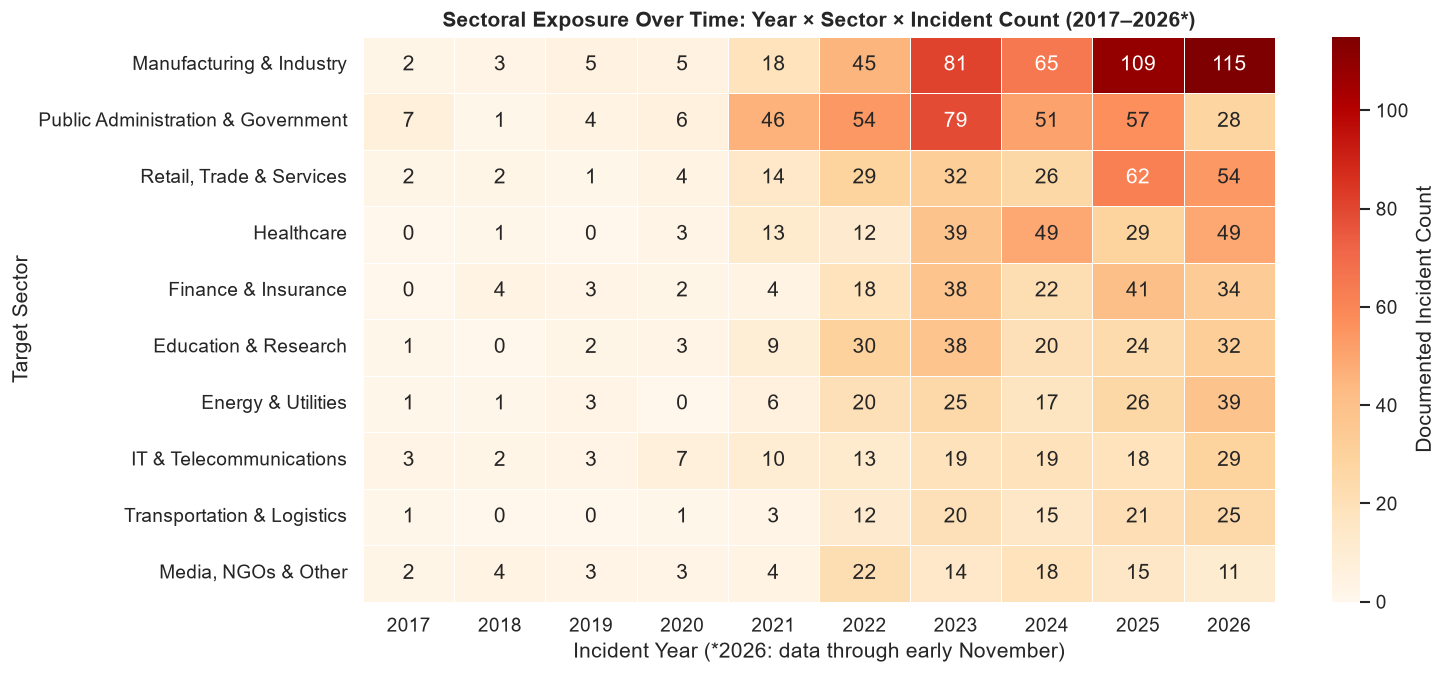

In [6]:
# Filter active multi-source observation window (2017–2026) for non-null sector records
sub_3v = df[(df["year"] >= 2017) & df["sector"].notna()].copy()

# Contingency matrix: Sector (rows) × Year (columns) containing incident counts (3rd variable)
pivot_3v = pd.crosstab(sub_3v["sector"], sub_3v["year"])

# Sort sectors descending by cumulative incident volume
sector_rank_3v = pivot_3v.sum(axis=1).sort_values(ascending=False).index
pivot_3v = pivot_3v.loc[sector_rank_3v]

plt.figure(figsize=(12.8, 5.8))
ax = sns.heatmap(
    pivot_3v,
    annot=True,
    fmt="d",
    cmap="OrRd",
    linewidths=0.5,
    cbar_kws={"label": "Documented Incident Count"},
)
ax.set_title("Sectoral Exposure Over Time: Year × Sector × Incident Count (2017–2026*)")
ax.set_xlabel("Incident Year (*2026: data through early November)")
ax.set_ylabel("Target Sector")
plt.tight_layout()
plt.show()

### Analytical Findings & Interpretation
- **Pre-2022 Baseline:** Prior to 2021, all sectors recorded fewer than 10 incidents per year. In **2021 and 2022**, the primary target was **Public Administration & Government** (46 and 54 incidents respectively, surpassing manufacturing), driven by municipal administration intrusions and geopolitical hacktivism following the 2022 invasion of Ukraine.
- **Post-2023 Industrial Pivot:** From 2023 onward, **Manufacturing & Industry** experienced an unprecedented escalation, rising from 81 incidents in 2023 to **109 in 2025** and **115 in 2026** (over double any other sector). Simultaneously, **Healthcare** sustained high pressure (49 incidents in both 2024 and 2026), and **Energy & Utilities** reached an all-time high of **39 incidents in 2026**.
- **Takeaway:** Threat volume has not expanded uniformly; commercial extortion actors have increasingly focused on industrial supply chains and critical utilities where downtime costs maximize extortion leverage.

---

## 6. Four-Variable Interactivity: Economic Weight vs. Incident Intensity

Using **Plotly**, we integrate the sector-year panel (2014–2025) into an interactive multi-dimensional bubble plot combining **four variables**:
1. **X-axis:** Mean Sector Gross Value Added — `GVA in Billion €` (logarithmic scale).
2. **Y-axis:** Cumulative Documented Incidents (2014–2025).
3. **Marker Size:** Mean Sector Workforce (`Thousands of Employees`).
4. **Marker Color:** Ransomware Concentration (`% of sector incidents attributed to ransomware`).

### Research Question 6
> *Do incident volumes scale proportionally with industry economic output and workforce, and which sectors exhibit disproportionate ransomware concentration?*

In [7]:
# Aggregate the sector-year panel across completed macroeconomic reporting years (2014–2025)
sec_agg = (
    df_panel[df_panel["year"] <= 2025]
    .groupby("sector", as_index=False)
    .agg(
        avg_gva_bn=("sec_gva_eur_bn", "mean"),
        avg_emp_k=("sec_employment_thousands", "mean"),
        total_incidents=("documented_incidents", "sum"),
        ransomware_incidents=("ransomware_incidents", "sum"),
        inc_per_10bn_gva=("incidents_per_10bn_eur_gva", "mean"),
    )
)

# Calculate 4th variable: proportion of ransomware incidents within each sector
sec_agg["ransomware_pct"] = (sec_agg["ransomware_incidents"] / sec_agg["total_incidents"] * 100).round(1)
sec_agg["avg_gva_bn"] = sec_agg["avg_gva_bn"].round(1)
sec_agg["avg_emp_mio"] = (sec_agg["avg_emp_k"] / 1000.0).round(2)
sec_agg["inc_per_10bn_gva"] = sec_agg["inc_per_10bn_gva"].round(2)

# Specific label alignments to prevent text overlapping across neighboring bubbles
pos_map = {
    "Finance & Insurance": "top left",
    "Education & Research": "middle right",
    "IT & Telecommunications": "middle right",
    "Media, NGOs & Other": "middle left",
    "Transportation & Logistics": "bottom center",
    "Retail, Trade & Services": "top left",
}
text_positions = [pos_map.get(s, "top center") for s in sec_agg["sector"]]

# Interactive 4-variable bubble chart
fig_4v = px.scatter(
    sec_agg,
    x="avg_gva_bn",
    y="total_incidents",
    size="avg_emp_k",
    color="ransomware_pct",
    text="sector",
    log_x=True,
    size_max=56,
    color_continuous_scale="Plasma",
    labels={
        "avg_gva_bn": "Mean Sector Gross Value Added — GVA (€ Billion, Log Scale)",
        "total_incidents": "Cumulative Incidents (2014–2025)",
        "avg_emp_k": "Workforce (Thousands)",
        "ransomware_pct": "Ransomware Share (%)",
    },
    hover_name="sector",
    hover_data={
        "avg_gva_bn": True,
        "total_incidents": True,
        "avg_emp_mio": True,
        "ransomware_pct": True,
        "inc_per_10bn_gva": True,
        "avg_emp_k": False,
        "sector": False,
    },
    title="4-Variable Coupling: Sector GVA × Cumulative Incidents × Workforce × Ransomware Share",
)

fig_4v.update_traces(
    textposition=text_positions,
    marker=dict(line=dict(width=1.5, color="DarkSlateGrey"), opacity=0.88),
)
fig_4v.update_layout(
    template="plotly_white",
    height=560,
    xaxis=dict(range=[np.log10(62), np.log10(1950)]),
    yaxis=dict(range=[30, 390]),
    margin=dict(l=50, r=40, t=65, b=50),
)

fig_4v.show()

### Analytical Findings & Interpretation
- **Divergence of the Two Peaks (Manufacturing vs. Public Administration):**
  - While both sectors recorded comparable total incident counts between 2014 and 2025 (**337** vs. **318**), they occupy opposite ends of the ransomware spectrum. **74.8%** of incidents targeting Manufacturing & Industry were ransomware, compared to just **10.4%** in Public Administration & Government (which is primarily targeted by DDoS and espionage).
  - Public Administration exhibits an extreme normalized risk rate of **1.16 incidents per €10B GVA**, compared to **0.36** in Manufacturing.
- **The Scale Anomaly (Retail, Trade & Services):**
  - Despite being the largest sector by economic output (**€1,294B GVA**) and workforce (**16.8 million employees**), Retail & Services recorded only **176 incidents**—yielding the lowest normalized incident rate (**0.10 per €10B GVA**).
- **High-Risk Niche Infrastructure (Energy & Finance):**
  - Energy & Utilities and Finance & Insurance operate at smaller output scales (€85.7B and €133.2B GVA), but experience high normalized threat rates (**0.77** and **0.75 incidents per €10B GVA**) paired with high ransomware vulnerability (52.0% and 58.6%).

---

## 7. Five-Variable Threat Architecture: End-to-End Incident Flow (Sankey)

To trace the complete attack lifecycle, we construct an interactive **Plotly Sankey diagram** linking **five variables**:
$$\text{1. Actor Type} \;\longrightarrow\; \text{2. Threat Motive} \;\longrightarrow\; \text{3. Attack Type} \;\longrightarrow\; \text{4. Target Sector} \;\longrightarrow\; \text{5. Consequence Profile}$$

### Research Question 7
> *How do threat actor category, strategic motive, attack vector, target sector, and operational outcome connect into distinct threat pipelines across the German incident landscape?*

In [8]:
# Filter records with complete coverage across actor, motive, attack type, and sector
sankey_df = df.dropna(subset=["actor_type", "motive", "attack_type", "sector"]).copy()
sankey_df = sankey_df[sankey_df["actor_type"].isin(["Criminal", "State-Sponsored", "Hacktivist"])]

# Focus target sector labels on the top 6 sectors to maintain optimal visual clarity
top6_sectors = sankey_df["sector"].value_counts().head(6).index.tolist()

sankey_df["s_actor"] = "Actor: " + sankey_df["actor_type"]
sankey_df["s_motive"] = "Motive: " + sankey_df["motive"]
sankey_df["s_attack"] = "Attack: " + sankey_df["attack_type"]
sankey_df["s_sector"] = sankey_df["sector"].apply(
    lambda s: f"Target: {s}" if s in top6_sectors else "Target: Other 4 Sectors"
)

def derive_consequence_profile(row) -> str:
    """Combines operational disruption and exfiltration flags into a consequence label."""
    disr = row["has_disruption"]
    theft = row["has_data_theft"]
    if disr is True and theft is True:
        return "Outcome: Dual Impact (Disruption + Theft)"
    if disr is True and theft is not True:
        return "Outcome: Operational Disruption Only"
    if disr is False and theft is True:
        return "Outcome: Exfiltration Only (No Disruption)"
    if pd.isna(disr) and theft is True:
        return "Outcome: Confirmed Theft (Disruption Unstated)"
    return "Outcome: Intrusion (No Impact Confirmed)"

sankey_df["s_outcome"] = sankey_df.apply(derive_consequence_profile, axis=1)

# Compile unique ordered nodes and index mapping across all five stages
stages = ["s_actor", "s_motive", "s_attack", "s_sector", "s_outcome"]
all_nodes = []
for st in stages:
    for val in sankey_df[st].unique():
        if val not in all_nodes:
            all_nodes.append(val)

node_idx = {name: i for i, name in enumerate(all_nodes)}

# Distinguish the 5 vertical stages with distinct color hues
stage_colors = {
    "Actor:":   "#2c3e50",
    "Motive:":  "#2980b9",
    "Attack:":  "#8e44ad",
    "Target:":  "#27ae60",
    "Outcome:": "#d35400",
}
node_colors = [
    next((c for prefix, c in stage_colors.items() if name.startswith(prefix)), "#7f8c8d")
    for name in all_nodes
]

# Aggregate pairwise transition links between successive stages
sources, targets, values = [], [], []
for s_col, t_col in zip(stages[:-1], stages[1:]):
    grouped = sankey_df.groupby([s_col, t_col]).size().reset_index(name="cnt")
    grouped = grouped[grouped["cnt"] >= 3]  # Prune low-frequency paths (n < 3) to reduce visual clutter
    for _, row in grouped.iterrows():
        sources.append(node_idx[row[s_col]])
        targets.append(node_idx[row[t_col]])
        values.append(int(row["cnt"]))

fig_5v = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        pad=14,
        thickness=18,
        line=dict(color="white", width=0.8),
        label=[n.split(": ", 1)[1] for n in all_nodes],
        color=node_colors,
        hovertemplate="<b>%{label}</b><br>Incidents in stage: %{value}<extra></extra>",
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="rgba(130, 150, 175, 0.32)",
        hovertemplate="%{source.label} → %{target.label}<br>Incident flow: <b>%{value}</b><extra></extra>",
    ),
)])

fig_5v.update_layout(
    title=(
        f"Interactive 5-Variable Threat Architecture (N = {len(sankey_df)})<br>"
        "<sup>1. Actor Classification  →  2. Motive  →  3. Attack Type  →  4. Target Sector  →  5. Consequence Profile</sup>"
    ),
    font=dict(size=11.5),
    height=610,
    margin=dict(l=20, r=20, t=75, b=25),
)

fig_5v.show()

### Analytical Findings & Interpretation
- **Three Distinct Threat Pipelines:**
  1. **The Commercial Extortion Pipeline:** `Criminal` $\rightarrow$ `Financial` $\rightarrow$ `Ransomware` $\rightarrow$ broad distribution across `Manufacturing & Industry`, `Retail`, `Finance`, and `Healthcare` $\rightarrow$ culminates in **Confirmed Theft** and **Dual Impact**.
  2. **The Espionage Pipeline:** `State-Sponsored` $\rightarrow$ `Espionage` $\rightarrow$ `System Intrusion / Malware` and `Data Breach` $\rightarrow$ strongly concentrated on `Public Administration & Government` $\rightarrow$ culminates in **Exfiltration Only (No Disruption)**, consistent with covert intelligence gathering.
  3. **The Ideological Disruption Pipeline:** `Hacktivist` $\rightarrow$ `Hacktivism / Protest` and `Sabotage` $\rightarrow$ `DDoS / Disruption` $\rightarrow$ targeted at `Public Administration` $\rightarrow$ terminates in **Operational Disruption Only**.
- **Implication for Threat Modeling:** The Sankey model demonstrates that security defenses cannot treat cyber threats as a homogeneous phenomenon. Industrial defense requires data exfiltration controls and extortion resistance, whereas public administration requires continuous threat hunting for stealth persistence alongside high-capacity DDoS mitigation.

---

## 8. Geospatial Distribution: Absolute Incident Count vs. Per-Capita Intensity

Integrating geolocated incidents with official Destatis regional statistics and federal state polygon boundaries (`germany_bundeslaender.geojson`), we compare **absolute incident counts** against **per-capita exposure (incidents per million residents)** across Germany's 16 federal states.

### Research Question 8
> *Which federal states bear the highest volume of cyber incidents, and how does the regional risk profile shift when controlling for population size?*

In [9]:
# Load local official polygon boundaries for all 16 German federal states
with open(RAW_DIR / "germany_bundeslaender.geojson", "r", encoding="utf-8") as f:
    geojson_de = json.load(f)

# Filter incident records possessing verified federal state attribution
df_geo = df[df["bundesland"].isin(BUNDESLAND_METRICS.keys())].copy()

# Compute regional metrics: count, KRITIS share, and top targeted sector
geo_rows = []
for en_state, meta in BUNDESLAND_METRICS.items():
    sub_s = df_geo[df_geo["bundesland"] == en_state]
    inc_cnt = len(sub_s)
    kritis_vals = sub_s["is_kritis_sector"].dropna().astype(bool)
    kritis_pct = round(kritis_vals.mean() * 100, 1) if len(kritis_vals) > 0 else 0.0
    sec_vals = sub_s["sector"].dropna()
    top_sec = sec_vals.mode().iloc[0] if len(sec_vals) > 0 else "N/A"

    geo_rows.append({
        "de_name": meta["de_name"],
        "en_name": en_state,
        "incidents": inc_cnt,
        "pop_mio": meta["pop_mio"],
        "gdp_bn": meta["gdp_bn"],
        "inc_per_mio": round(inc_cnt / meta["pop_mio"], 1),
        "kritis_pct": kritis_pct,
        "top_sector": top_sec,
    })

geo_df = pd.DataFrame(geo_rows)

# Dual-panel interactive choropleth map
fig_map = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "choropleth"}, {"type": "choropleth"}]],
    subplot_titles=(
        "a) Absolute Documented Incidents",
        "b) Density: Incidents per Million Residents",
    ),
)

custom_cols = geo_df[["incidents", "inc_per_mio", "pop_mio", "gdp_bn", "kritis_pct", "top_sector"]].values
hover_tmpl = (
    "<b>%{location}</b><br>"
    "Incident Count: <b>%{customdata[0]}</b><br>"
    "Density: <b>%{customdata[1]} / 1M Pop.</b><br>"
    "Population: %{customdata[2]}M | GDP: €%{customdata[3]}B<br>"
    "KRITIS Share: %{customdata[4]}%<br>"
    "Primary Target: %{customdata[5]}<extra></extra>"
)

# Left panel: Absolute incident volume
fig_map.add_trace(
    go.Choropleth(
        geojson=geojson_de,
        featureidkey="properties.name",
        locations=geo_df["de_name"],
        z=geo_df["incidents"],
        colorscale="Blues",
        marker_line_color="white",
        marker_line_width=1.0,
        colorbar=dict(title="Incidents", x=0.45, len=0.78, thickness=14),
        customdata=custom_cols,
        hovertemplate=hover_tmpl,
    ),
    row=1,
    col=1,
)

# Right panel: Population-normalized incident rate
fig_map.add_trace(
    go.Choropleth(
        geojson=geojson_de,
        featureidkey="properties.name",
        locations=geo_df["de_name"],
        z=geo_df["inc_per_mio"],
        colorscale="YlOrRd",
        marker_line_color="white",
        marker_line_width=1.0,
        colorbar=dict(title="Inc. / 1M Pop.", x=1.0, len=0.78, thickness=14),
        customdata=custom_cols,
        hovertemplate=hover_tmpl,
    ),
    row=1,
    col=2,
)

fig_map.update_geos(fitbounds="locations", visible=False)
fig_map.update_layout(
    title="Geospatial Distribution of Cyber Incidents Across German Federal States (N = 1,159)",
    height=560,
    margin=dict(l=10, r=20, t=70, b=10),
)

fig_map.show()

### Analytical Findings & Interpretation
- **Absolute Count Distribution (Left Map):** Absolute incident volume closely traces the demographic and industrial weight of Germany: **North Rhine-Westphalia (242 incidents)**, **Bavaria (192)**, and **Baden-Württemberg (159)** lead by a wide margin. In North Rhine-Westphalia, Manufacturing & Industry constitutes the dominant target.
- **Population-Normalized Density (Right Map):** Normalizing by population inverts the hierarchy:
  - The highest exposure density appears in city-states and major financial/logistical hubs: **Hamburg (25.1 incidents / million)** (where Finance & Insurance dominates), **Bremen (24.6 / million)**, and **Berlin (23.5 / million)**.
  - Among territorial states, **Mecklenburg-Vorpommern (23.3 / million)** ranks exceptionally high due to widespread public administration targeting (83.8% KRITIS share), followed by **Hesse (15.3 / million)** centered on the Frankfurt financial cluster.
- **Conclusion:** Evaluating raw incident counts alone primarily reproduces a population map. Per-capita normalization demonstrates that organizational cyber incident density is highest in urban administrative, logistics, and financial centers.

---

## 9. Synthesis of Findings & Key Takeaways

| Analytical Dimension | Core Empirical Finding | Implication for Risk Management |
|---|---|---|
| **Data Diagnostics (RQ 1)** | High coverage across core attributes (73–100%); rule-based enrichment added 80 verified cells without synthetic imputation. | Models avoid artificial bias from default values in impact and motive tags. |
| **Longitudinal Trends (RQ 2)** | Rapid escalation post-2021 (reaching 504 incidents in 2026); Manufacturing (453) and Public Admin (358) form primary targets. | Protection strategies must prioritize manufacturing supply chains and KRITIS. |
| **Coupled Mechanisms (RQ 3–4)** | Near-deterministic Actor $\leftrightarrow$ Motive coupling ($V = 0.94$); Ransomware combines 97% theft and 91% disruption (double extortion). | Backups alone are insufficient; data exfiltration prevention is paramount. |
| **Multi-Dimensional Shifts (RQ 5–7)** | Industrial targeting accelerated post-2023; Public Admin bears highest normalized rate (1.16 inc./€10B GVA) with 10.4% ransomware. | Requires segmented defense: anti-extortion for industry vs. APT/DDoS defense for government. |
| **Geospatial Exposure (RQ 8)** | Absolute volumes concentrate in NRW, Bavaria, and BW; per-capita intensity peaks in Hamburg (25.1/M), Bremen (24.6/M), and Berlin (23.5/M). | Incident response infrastructure (CERTs) must align with organizational headquarters density. |